# **FINAL EXAM DEEP LEARNING**

**NO 1**  
**Nama  : Stevanus Gerald Marconus**  
**NIM   : 2802392500**

**LAMPIRAN:**  
Link -> https://youtu.be/_8oKm-wl6xI 

In [1]:
!pip install statsmodels -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import random, os
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

### **A. Lakukan eksplorasi data. Pisahkan data time series tersebut menjadi dua bagian input dan output dengan window size = 5 dan horizon = 1 . Pisahkan data training menjadi train set dan validation set dengan proporsi 90% untuk train set dan 10% untuk validation set.**

#### **A.1 Import Data and OVerview**

In [3]:
# import data
aapl_data = pd.read_csv('AAPL.csv')
amd_data = pd.read_csv('AMD.csv')

**DATA AAPL**

In [4]:
aapl_data.head(7)

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400
5,1980-12-19,0.504464,0.506696,0.504464,0.504464,0.399707,12157600
6,1980-12-22,0.529018,0.531250,0.529018,0.529018,0.419162,9340800


In [5]:
aapl_data.tail(7)

,Date,Open,High,Low,Close,Adj Close,Volume
9902,2020-03-24,236.360001,247.690002,234.300003,246.880005,246.880005,71882800
9903,2020-03-25,250.750000,258.250000,244.300003,245.520004,245.520004,75900500
9904,2020-03-26,246.520004,258.679993,246.360001,258.440002,258.440002,63021800
9905,2020-03-27,252.750000,255.869995,247.050003,247.740005,247.740005,51054200
9906,2020-03-30,250.740005,255.520004,249.399994,254.809998,254.809998,41994100
9907,2020-03-31,255.600006,262.489990,252.000000,254.289993,254.289993,49250500
9908,2020-04-01,246.500000,248.720001,239.130005,240.910004,240.910004,43956200


In [6]:
aapl_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9909 entries, 0 to 9908
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       9909 non-null   object 
 1   Open       9909 non-null   float64
 2   High       9909 non-null   float64
 3   Low        9909 non-null   float64
 4   Close      9909 non-null   float64
 5   Adj Close  9909 non-null   float64
 6   Volume     9909 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 542.0+ KB


In [7]:
aapl_data.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [8]:
print(f"Duplicated data {aapl_data.duplicated().sum()}")

Duplicated data 0


In [9]:
# check the date range of the data
aapl_data['Date'] = pd.to_datetime(aapl_data['Date'])
print('AAPL Periode:', aapl_data['Date'].min().date(), 'to', aapl_data['Date'].max().date())

AAPL Periode: 1980-12-12 to 2020-04-01


In [10]:
aapl_data.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,9909,2000-07-30 08:33:08.010899200,1980-12-12 00:00:00,1990-10-02 00:00:00,2000-07-21 00:00:00,2010-05-28 00:00:00,2020-04-01 00:00:00,NaN
Open,9909.0,32.606849,0.198661,1.071429,1.729286,35.799999,324.73999,58.415759
High,9909.0,32.936079,0.198661,1.089286,1.758929,36.265713,327.850006,59.001576
Low,9909.0,32.27756,0.196429,1.048571,1.696429,35.328571,323.350006,57.883037
Close,9909.0,32.61803,0.196429,1.071429,1.732143,35.761429,327.200012,58.471899
Adj Close,9909.0,30.57657,0.155638,0.917643,1.466154,31.042374,327.200012,56.746275
Volume,9909.0,85829159.299627,347200.0,33042300.0,57664900.0,106999200.0,1855410200.0,85971948.761355



**DATA AMD**

In [11]:
amd_data.head(7)

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-03-17,0.0,3.302083,3.125000,3.145833,3.145833,219600
1,1980-03-18,0.0,3.125000,2.937500,3.031250,3.031250,727200
2,1980-03-19,0.0,3.083333,3.020833,3.041667,3.041667,295200
3,1980-03-20,0.0,3.062500,3.010417,3.010417,3.010417,159600
4,1980-03-21,0.0,3.020833,2.906250,2.916667,2.916667,130800
5,1980-03-24,0.0,2.916667,2.635417,2.666667,2.666667,436800
6,1980-03-25,0.0,2.750000,2.552083,2.604167,2.604167,645600


In [12]:
amd_data.tail(7)

,Date,Open,High,Low,Close,Adj Close,Volume
10091,2020-03-24,44.040001,46.810001,43.990002,46.220001,46.220001,106794200
10092,2020-03-25,46.790001,47.880001,44.430000,44.630001,44.630001,93760400
10093,2020-03-26,45.779999,47.500000,45.400002,47.500000,47.500000,73680200
10094,2020-03-27,46.320000,47.980000,45.900002,46.580002,46.580002,74599200
10095,2020-03-30,47.240002,48.459999,46.660000,47.860001,47.860001,68486600
10096,2020-03-31,47.930000,48.529999,45.160000,45.480000,45.480000,83483700
10097,2020-04-01,44.180000,46.849998,43.160000,43.660000,43.660000,91895000


In [13]:
amd_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10098 entries, 0 to 10097
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10098 non-null  object 
 1   Open       10098 non-null  float64
 2   High       10098 non-null  float64
 3   Low        10098 non-null  float64
 4   Close      10098 non-null  float64
 5   Adj Close  10098 non-null  float64
 6   Volume     10098 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 552.4+ KB


In [14]:
amd_data.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [15]:
print(f"Duplicated data {amd_data.duplicated().sum()}")

Duplicated data 0


In [16]:
# check the date range of the data
amd_data['Date'] = pd.to_datetime(amd_data['Date'])
print('AMD Periode:', amd_data['Date'].min().date(), 'to', amd_data['Date'].max().date())

AMD Periode: 1980-03-17 to 2020-04-01


In [17]:
amd_data.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,10098,2000-03-15 15:28:29.090909056,1980-03-17 00:00:00,1990-03-12 06:00:00,2000-03-07 12:00:00,2010-03-22 18:00:00,2020-04-01 00:00:00,NaN
Open,10098.0,10.889136,0.0,4.5625,9.0625,14.7475,58.439999,8.615288
High,10098.0,11.462153,1.69,5.0625,9.280625,15.0,59.27,8.475056
Low,10098.0,10.958702,1.61,4.8125,8.875,14.435625,57.509998,8.077069
Close,10098.0,11.210802,1.62,4.9375,9.0625,14.7075,58.900002,8.283645
Adj Close,10098.0,11.210802,1.62,4.9375,9.0625,14.7075,58.900002,8.283645
Volume,10098.0,14516250.722915,0.0,1098600.0,5518500.0,17427225.0,325058400.0,23961991.012332


#### **A.2 Exploration and Feature Selection**

**Feature Selection**

Berdasarkan hasil overview data dari kedua dataset yang ada, bisa kita  lhat bahwa keseluruhan fiturnya berupa numerical, dan untuk label targetnya sendiri pun berupa harga pasar pada hari tersebut.  Untuk case kali ini saya memilih menggunakan Harga Close dibandingkan menggunakan fitur harga yang lain, karena berdasarkan common knowledge yang dijadikan catatan harga pada hari itu adalah catatan harga close, yang berarti hari itu sudah selesai.  

Didukung juga dengan cek korelasi yang menunjukkan bahwa fitur harga Open, High, Low, dan Adj Close memiliki Korelasi yang sangat tinggi dan bahkan hingga multikolinearitas yang tinggi, sehingga beresiko jika kita gunakan selain close akan menimbulkan caacat pada data train karena bisa menimbulkan redundan.

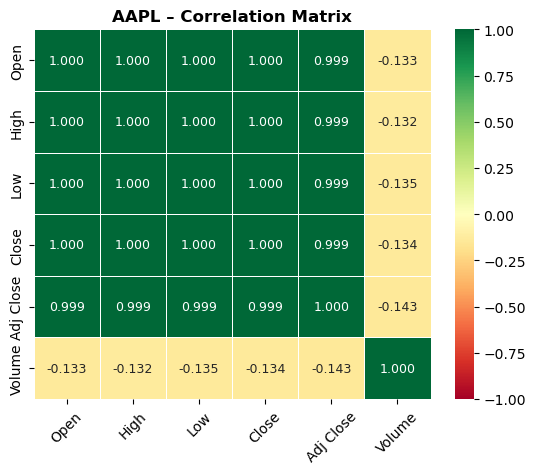

In [18]:
numeric_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

# AAPL Correlation
corr_aapl = aapl_data[numeric_cols].corr()
mask_a = np.zeros_like(corr_aapl, dtype=bool)
mask_a[np.triu_indices_from(mask_a, k=1)] = True
sns.heatmap(corr_aapl, annot=True, fmt='.3f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, 
            linewidths=0.5, annot_kws={'size': 9})
plt.title('AAPL – Correlation Matrix', fontweight='bold', fontsize=12)
plt.tick_params(axis='x', rotation=45)

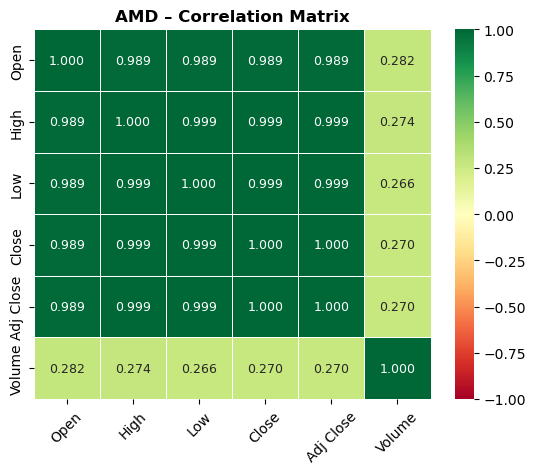

In [19]:
# AMD Correlation
corr_amd = amd_data[numeric_cols].corr()
sns.heatmap(corr_amd, annot=True, fmt='.3f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, 
            linewidths=0.5, annot_kws={'size': 9})
plt.title('AMD – Correlation Matrix', fontweight='bold', fontsize=12)
plt.tick_params(axis='x', rotation=45)


In [20]:
# Check correlation with Close price
corr_aapl_close = aapl_data[numeric_cols].corr()['Close'].drop('Close')
corr_amd_close  = amd_data[numeric_cols].corr()['Close'].drop('Close')

df_corr = pd.DataFrame({
    'Korelasi dengan Close (AAPL)': corr_aapl_close,
    'Korelasi dengan Close (AMD)' : corr_amd_close
})

display(df_corr.style.format('{:.4f}').background_gradient(cmap='RdYlGn', vmin=-1, vmax=1).set_caption('Korelasi Setiap Kolom terhadap Close Price'))

,Korelasi dengan Close (AAPL),Korelasi dengan Close (AMD)
Open,0.9999,0.9887
High,0.9999,0.9994
Low,0.9999,0.9993
Adj Close,0.9991,1.0000
Volume,-0.1337,0.2701


**Check Outlier**

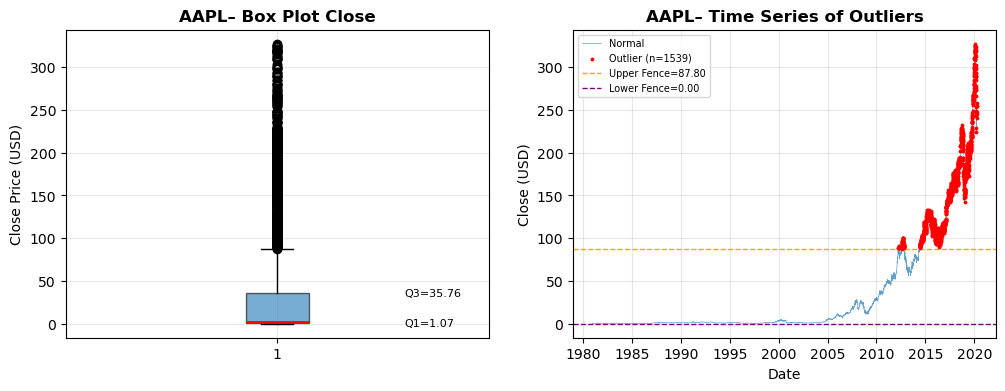

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes = axes.flatten()
close = aapl_data['Close']
Q1  = close.quantile(0.25)
Q3  = close.quantile(0.75)
IQR = Q3 - Q1
lb  = Q1 - 1.5 * IQR
ub  = Q3 + 1.5 * IQR
outliers = aapl_data[(close < lb) | (close > ub)]

# Box Plot
axes[0].boxplot(close, vert=True, patch_artist=True,
                      boxprops=dict(facecolor='#1f77b4', alpha=0.6),
                      medianprops=dict(color='red', linewidth=2))
axes[0].set_title(f'AAPL– Box Plot Close', fontweight='bold')
axes[0].set_ylabel('Close Price (USD)')
axes[0].text(1.3, Q3, f'Q3={Q3:.2f}', va='center', fontsize=8)
axes[0].text(1.3, Q1, f'Q1={Q1:.2f}', va='center', fontsize=8)
axes[0].grid(True, alpha=0.3)

# Outlier Time Series
axes[1].plot(aapl_data['Date'], close, color='#1f77b4', linewidth=0.5, alpha=0.7, label='Normal')
axes[1].scatter(outliers['Date'], outliers['Close'],
                        color='red', s=3, zorder=5, label=f'Outlier (n={len(outliers)})')
axes[1].axhline(ub, color='orange', linestyle='--', linewidth=1, label=f'Upper Fence={ub:.2f}')
axes[1].axhline(max(lb, 0), color='purple', linestyle='--', linewidth=1, label=f'Lower Fence={max(lb,0):.2f}')
axes[1].set_title(f'AAPL– Time Series of Outliers', fontweight='bold')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Close (USD)')
axes[1].legend(fontsize=7); axes[1].grid(True, alpha=0.3)


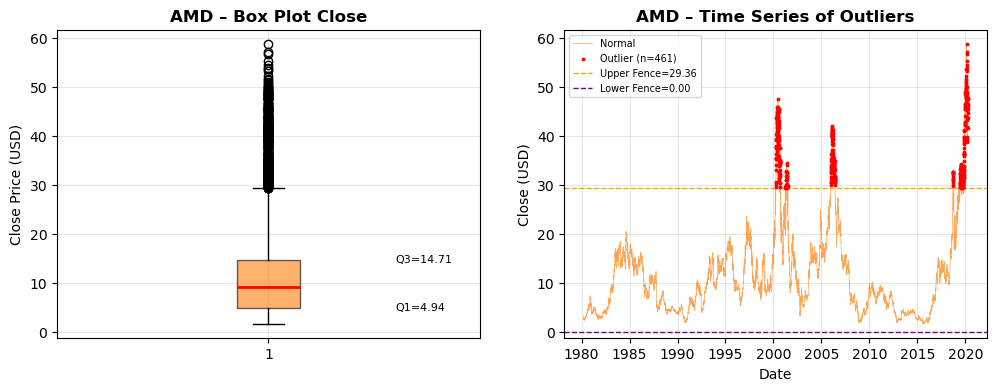

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes = axes.flatten()
close = amd_data['Close']
Q1  = close.quantile(0.25)
Q3  = close.quantile(0.75)
IQR = Q3 - Q1
lb  = Q1 - 1.5 * IQR
ub  = Q3 + 1.5 * IQR
outliers = amd_data[(close < lb) | (close > ub)]

axes[0].boxplot(close, vert=True, patch_artist=True,
                      boxprops=dict(facecolor='#ff7f0e', alpha=0.6),
                      medianprops=dict(color='red', linewidth=2))
axes[0].set_title(f'AMD – Box Plot Close', fontweight='bold')
axes[0].set_ylabel('Close Price (USD)')
axes[0].text(1.3, Q3, f'Q3={Q3:.2f}', va='center', fontsize=8)
axes[0].text(1.3, Q1, f'Q1={Q1:.2f}', va='center', fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].plot(amd_data['Date'], close, color='#ff7f0e', linewidth=0.5, alpha=0.7, label='Normal')
axes[1].scatter(outliers['Date'], outliers['Close'],
                        color='red', s=3, zorder=5, label=f'Outlier (n={len(outliers)})')
axes[1].axhline(ub, color='orange', linestyle='--', linewidth=1, label=f'Upper Fence={ub:.2f}')
axes[1].axhline(max(lb, 0), color='purple', linestyle='--', linewidth=1, label=f'Lower Fence={max(lb,0):.2f}')
axes[1].set_title(f'AMD – Time Series of Outliers', fontweight='bold')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Close (USD)')
axes[1].legend(fontsize=7); axes[1].grid(True, alpha=0.3)


**Keputusan terhadap Outlier:**  

Outlier Tetap dipakai karena:
1. **Outlier = Kejadian Nyata Pasar**: Harga saham yang teridentifikasi sebagai outlier justru merepresentasikan kejadian historis penting, misalnya kaya crash pasar 2000 (dot-com bubble), crash 2008 (financial crisis), atau rally AMD 2016 (+295%). Menghapusnya berarti menghilangkan informasi penting tentang volatilitas pasar.
2. **LSTM Robust terhadap Skewed Distribution**: Normalisasi MinMaxScaler sudah cukup untuk mengatasi perbedaan skala, tanpa perlu menghapus data.
3. **Domain Knowledge**: Dalam prediksi saham, kemampuan model untuk mengenali dan mengantisipasi kondisi ekstrem adalah nilai tambah, bukan kelemahan.


**Check Distribution CLOSE**

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_25348\1065752991.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(years_data, labels=years_labels, patch_artist=True,


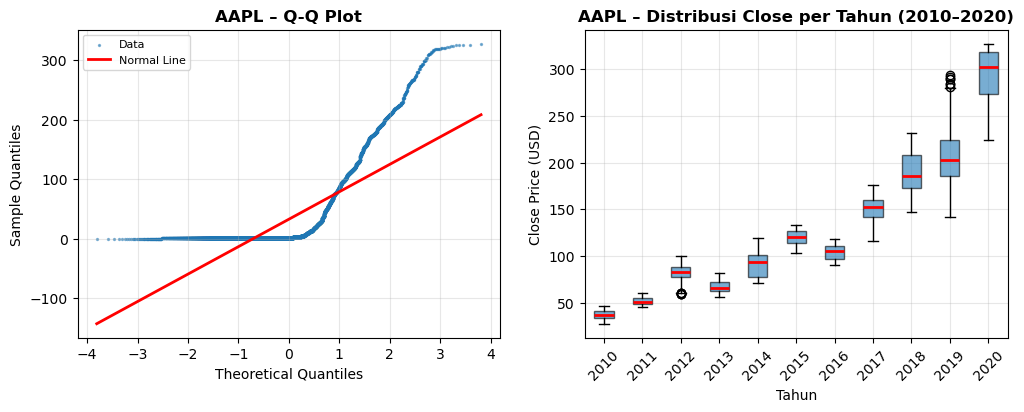

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
close = aapl_data['Close']
sk = stats.skew(close)
ku = stats.kurtosis(close)

# Q-Q Plot
(osm, osr), (slope, intercept, r) = stats.probplot(close, dist='norm')
axes[0].scatter(osm, osr, color='#1f77b4', s=2, alpha=0.5, label='Data')
axes[0].plot([osm.min(), osm.max()],
                        [slope*osm.min()+intercept, slope*osm.max()+intercept],
                        'r-', linewidth=2, label='Normal Line')
axes[0].set_title(f'AAPL – Q-Q Plot', fontweight='bold')
axes[0].set_xlabel('Theoretical Quantiles'); axes[0].set_ylabel('Sample Quantiles')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# Year-by-Year Box Plot (10 tahun terakhir)
df_plot = aapl_data.copy()
df_plot['Year'] = df_plot['Date'].dt.year
recent = df_plot[df_plot['Year'] >= 2010]
years_data = [grp['Close'].values for _, grp in recent.groupby('Year')]
years_labels = sorted(recent['Year'].unique())
bp = axes[1].boxplot(years_data, labels=years_labels, patch_artist=True,
                               medianprops=dict(color='red', linewidth=2))
for patch in bp['boxes']:
        patch.set_facecolor('#1f77b4'); patch.set_alpha(0.6)
axes[1].set_title(f'AAPL – Distribusi Close per Tahun (2010–2020)', fontweight='bold')
axes[1].set_xlabel('Tahun'); axes[1].set_ylabel('Close Price (USD)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_25348\2495941013.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(years_data, labels=years_labels, patch_artist=True,


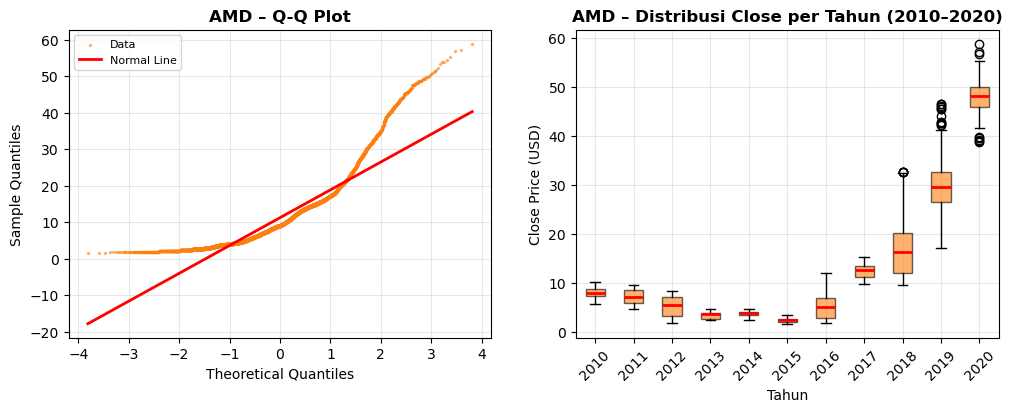

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
close = amd_data['Close']
sk = stats.skew(close)
ku = stats.kurtosis(close)

# Q-Q Plot
(osm, osr), (slope, intercept, r) = stats.probplot(close, dist='norm')
axes[0].scatter(osm, osr, color='#ff7f0e', s=2, alpha=0.5, label='Data')
axes[0].plot([osm.min(), osm.max()],
                        [slope*osm.min()+intercept, slope*osm.max()+intercept],
                        'r-', linewidth=2, label='Normal Line')
axes[0].set_title(f'AMD – Q-Q Plot', fontweight='bold')
axes[0].set_xlabel('Theoretical Quantiles'); axes[0].set_ylabel('Sample Quantiles')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# Year-by-Year Box Plot (10 tahun terakhir)
df_plot = amd_data.copy()
df_plot['Year'] = df_plot['Date'].dt.year
recent = df_plot[df_plot['Year'] >= 2010]
years_data = [grp['Close'].values for _, grp in recent.groupby('Year')]
years_labels = sorted(recent['Year'].unique())
bp = axes[1].boxplot(years_data, labels=years_labels, patch_artist=True,
                               medianprops=dict(color='red', linewidth=2))
for patch in bp['boxes']:
        patch.set_facecolor('#ff7f0e'); patch.set_alpha(0.6)
axes[1].set_title(f'AMD – Distribusi Close per Tahun (2010–2020)', fontweight='bold')
axes[1].set_xlabel('Tahun'); axes[1].set_ylabel('Close Price (USD)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

**Time Series Information**

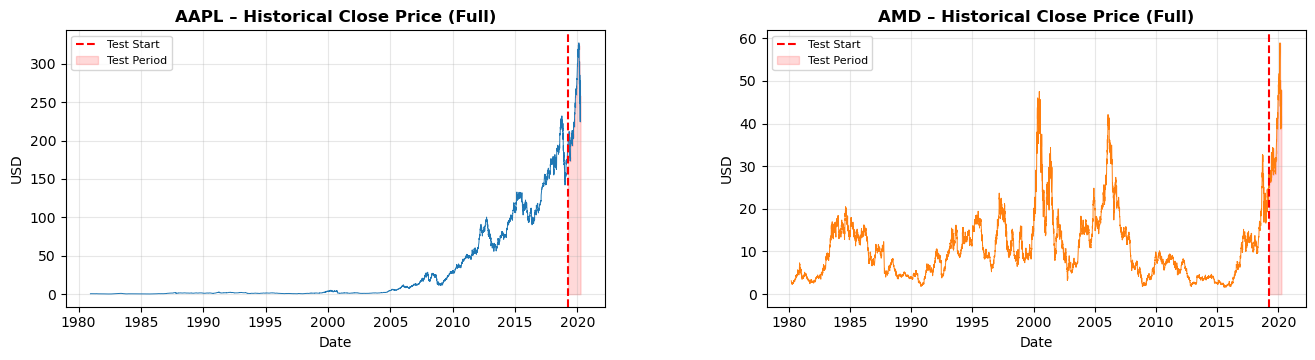

In [25]:
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.3)
TEST_LINE = pd.Timestamp('2019-04-01')
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(aapl_data['Date'], aapl_data['Close'], color='#1f77b4', linewidth=0.7)
ax1.axvline(TEST_LINE, color='red', linestyle='--', linewidth=1.5, label='Test Start')
ax1.fill_between(aapl_data['Date'], aapl_data['Close'],
                 where=aapl_data['Date'] >= TEST_LINE, alpha=0.15, color='red', label='Test Period')
ax1.set_title('AAPL – Historical Close Price (Full)', fontweight='bold')
ax1.set_xlabel('Date'); ax1.set_ylabel('USD'); ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(amd_data['Date'], amd_data['Close'], color='#ff7f0e', linewidth=0.7)
ax2.axvline(TEST_LINE, color='red', linestyle='--', linewidth=1.5, label='Test Start')
ax2.fill_between(amd_data['Date'], amd_data['Close'],
                 where=amd_data['Date'] >= TEST_LINE, alpha=0.15, color='red', label='Test Period')
ax2.set_title('AMD – Historical Close Price (Full)', fontweight='bold')
ax2.set_xlabel('Date'); ax2.set_ylabel('USD'); ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)


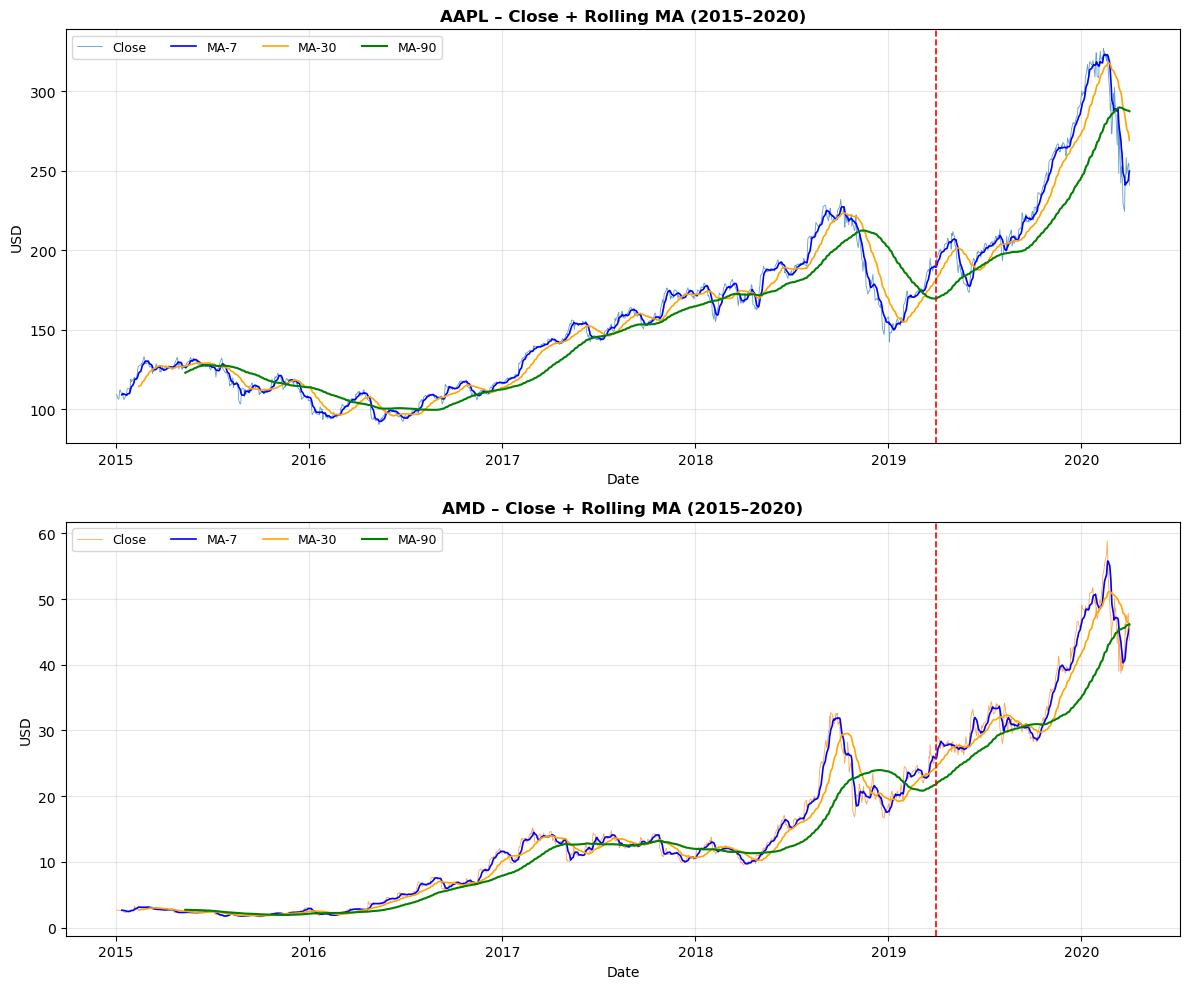

In [26]:
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(2, 1) 

data_list = [
    ('AAPL', aapl_data, '#1f77b4'),
    ('AMD',  amd_data,  '#ff7f0e')
]

for row, (name, df, color) in enumerate(data_list):
    ax = fig.add_subplot(gs[row, 0])
    recent = df[df['Date'] >= '2015-01-01'].copy()
    recent['MA7'] = recent['Close'].rolling(7).mean()
    recent['MA30'] = recent['Close'].rolling(30).mean()
    recent['MA90'] = recent['Close'].rolling(90).mean()
    ax.plot(recent['Date'], recent['Close'], color=color, linewidth=0.6, alpha=0.7, label='Close')
    ax.plot(recent['Date'], recent['MA7'], color='blue', linewidth=1.2, label='MA-7')
    ax.plot(recent['Date'], recent['MA30'], color='orange', linewidth=1.2, label='MA-30')
    ax.plot(recent['Date'], recent['MA90'], color='green', linewidth=1.5, label='MA-90')
    ax.axvline(TEST_LINE, color='red', linestyle='--', linewidth=1.2)
    ax.set_title(f'{name} – Close + Rolling MA (2015–2020)', fontweight='bold')
    ax.set_xlabel('Date'); ax.set_ylabel('USD')
    ax.legend(fontsize=9, ncol=4); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

AAPL:
- Harga menunjukkan tren naik jangka panjang yang konsisten sejak pertengahan 2016, dikonfirmasi oleh MA-90 (hijau) yang terus menanjak.
- Terlihat koreksi tajam di akhir 2018 (harga turun dari ~$230 ke ~$150), di mana MA-7 menembus ke bawah MA-30 dan MA-90 sinyal pelemahan momentum jangka pendek.
 MA-7 (biru) paling responsif terhadap fluktuasi harian, sementara MA-90 (hijau) paling halus dan menggambarkan arah tren utama.
- Pada periode test (setelah garis merah), harga melonjak hingga puncak ~$327 di awal 2020, lalu anjlok drastis akibat crash pasar Maret 2020 (awal pandemi COVID-19) terlihat dari MA-7 yang menukik tajam di ujung kanan.

AMD:
- Pola serupa namun dengan volatilitas lebih tinggi: harga melonjak dramatis dari ~$2 (2016) ke ~$58 (2020), kenaikan yang jauh lebih curam secara proporsional dibanding AAPL.
- Terdapat lonjakan dan koreksi besar di 2018 (naik ke ~$32 lalu turun ke ~$17), menunjukkan karakter saham yang lebih spekulatif.
- Pada periode test, AMD juga mengalami tren naik kuat diikuti koreksi di Maret 2020, sejalan dengan kondisi pasar global.

#### **A.3 Preprocessing**

In [27]:
# Remove uninformed Feature
aapl_df = aapl_data.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])
amd_df  = amd_data.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])

In [28]:
aapl_df.head(3)

,Date,Close
0,1980-12-12,0.513393
1,1980-12-15,0.486607
2,1980-12-16,0.450893


In [29]:
amd_df.head(3)

,Date,Close
0,1980-03-17,3.145833
1,1980-03-18,3.031250
2,1980-03-19,3.041667


##### **A.3.1 Train Test SPlit**

In [30]:
TEST_START_AAPL = aapl_df['Date'].max() - pd.DateOffset(years=1)
TEST_START_AMD = amd_df['Date'].max() - pd.DateOffset(years=1)

aapl_train = aapl_df[aapl_df['Date'] < TEST_START_AAPL].copy()
aapl_test = aapl_df[aapl_df['Date'] >= TEST_START_AAPL].copy()

amd_train = amd_df[amd_df['Date'] < TEST_START_AMD].copy()
amd_test = amd_df[amd_df['Date'] >= TEST_START_AMD].copy()

split_summary = pd.DataFrame({
    'Stock': ['AAPL', 'AMD'],
    'Total Records': [len(aapl_df), len(amd_df)],
    'Training Records': [len(aapl_train), len(amd_train)],
    'Test Records': [len(aapl_test), len(amd_test)],
    'Training %': [f'{len(aapl_train)/len(aapl_df)*100:.1f}%', f'{len(amd_train)/len(amd_df)*100:.1f}%'],
    'Test %': [f'{len(aapl_test)/len(aapl_df)*100:.1f}%', f'{len(amd_test)/len(amd_df)*100:.1f}%'],
    'Train Period': [f'{aapl_train["Date"].min().date()} – {aapl_train["Date"].max().date()}',
                    f'{amd_train["Date"].min().date()} – {amd_train["Date"].max().date()}'],
    'Test Period':  [f'{aapl_test["Date"].min().date()} – {aapl_test["Date"].max().date()}',
                    f'{amd_test["Date"].min().date()} – {amd_test["Date"].max().date()}']
})
display(split_summary.set_index('Stock').style.set_caption('Train-Test Split Summary'))

,Total Records,Training Records,Test Records,Training %,Test %,Train Period,Test Period
Stock,,,,,,,
AAPL,9909,9655,254,97.4%,2.6%,1980-12-12 – 2019-03-29,2019-04-01 – 2020-04-01
AMD,10098,9844,254,97.5%,2.5%,1980-03-17 – 2019-03-29,2019-04-01 – 2020-04-01


In [31]:
# Diagnosis penting: apakah harga test melebihi range training?
for name, df in [('AAPL', aapl_df), ('AMD', amd_df)]:
    tr = df[df['Date'] < TEST_START_AAPL]
    te = df[df['Date'] >= TEST_START_AMD]
    tr_max, tr_min = tr['Close'].max(), tr['Close'].min()
    over  = (te['Close'] > tr_max).sum()
    print(f'{name}:')
    print(f'Training range : [{tr_min:.2f}, {tr_max:.2f}]')
    print(f'Test range     : [{te["Close"].min():.2f}, {te["Close"].max():.2f}]')
    print(f'Hari test dengan harga > training max : {over}/{len(te)} ({over/len(te)*100:.1f}%)')
    print()

AAPL:
Training range : [0.20, 232.07]
Test range     : [173.30, 327.20]
Hari test dengan harga > training max : 117/254 (46.1%)

AMD:
Training range : [1.62, 47.50]
Test range     : [26.24, 58.90]
Hari test dengan harga > training max : 40/254 (15.7%)



##### **A.3.2 SCALING**

In [32]:
# USe MinMaxScaler untuk baseline
aapl_scaler = MinMaxScaler(feature_range=(0, 1))
amd_scaler  = MinMaxScaler(feature_range=(0, 1))

aapl_train_scaled = aapl_scaler.fit_transform(aapl_train[['Close']])
aapl_test_scaled  = aapl_scaler.transform(aapl_test[['Close']])

amd_train_scaled  = amd_scaler.fit_transform(amd_train[['Close']])
amd_test_scaled   = amd_scaler.transform(amd_test[['Close']])

##### **A.3.3 Set Sliding Window**

In [33]:
def create_windows(data, window_size=5, horizon=1):
    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i : i + window_size, 0])
        y.append(data[i + window_size : i + window_size + horizon, 0])
    return np.array(X), np.array(y)

WINDOW_SIZE = 5
HORIZON     = 1

X_aapl, y_aapl = create_windows(aapl_train_scaled, WINDOW_SIZE, HORIZON)
X_amd,  y_amd  = create_windows(amd_train_scaled,  WINDOW_SIZE, HORIZON)

X_aapl_test, y_aapl_test = create_windows(np.concatenate([aapl_train_scaled[-WINDOW_SIZE:], aapl_test_scaled]), WINDOW_SIZE, HORIZON)
X_amd_test,  y_amd_test  = create_windows(np.concatenate([amd_train_scaled[-WINDOW_SIZE:],  amd_test_scaled]),  WINDOW_SIZE, HORIZON)

##### **A.3.4 Train Val Split**

In [34]:
def split_tv(X, y, val=0.10):
    i = int(len(X)*(1-val))
    return X[:i], X[i:], y[:i], y[i:]

def rs(X): return X.reshape(X.shape[0], X.shape[1], 1)

X_aapl_train,X_aapl_val,y_aapl_train,y_aapl_val = split_tv(X_aapl, y_aapl)
X_amd_train,X_amd_val,y_amd_train,y_amd_val = split_tv(X_amd,  y_amd)

X_aapl_train,X_aapl_val = rs(X_aapl_train),rs(X_aapl_val); X_aapl_test=rs(X_aapl_test)
X_amd_train,X_amd_val = rs(X_amd_train),rs(X_amd_val); X_amd_test =rs(X_amd_test)

y_aapl_train,y_aapl_val,y_aapl_test = y_aapl_train.flatten(),y_aapl_val.flatten(),y_aapl_test.flatten()
y_amd_train,y_amd_val,y_amd_test  = y_amd_train.flatten(),y_amd_val.flatten(),y_amd_test.flatten()


### **B. Buatlah arsitektur baseline dengan LSTM (units=50) dan layer akhir berupa node Perceptron dengan units=1. Activation function untuk LSTM menggunakan ReLU**


#### **B.1 Modeling (BaseLine)** 

##### **B.1.1 AAPL Base Model**

In [35]:
model1_aapl= Sequential([
    LSTM(50, activation='relu', input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [36]:
model1_aapl.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True
)

In [38]:
model1_aapl.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae','mape']
)

In [39]:
history_aapl = model1_aapl.fit(
    X_aapl_train, y_aapl_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_aapl_val, y_aapl_val),
    callbacks = [early_stop],
    verbose = 1
)

Epoch 1/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0034 - mae: 0.0259 - mape: 599.4850 - val_loss: 2.9555e-04 - val_mae: 0.0126 - val_mape: 2.0074
Epoch 2/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.3267e-05 - mae: 0.0019 - mape: 125.7387 - val_loss: 2.7849e-04 - val_mae: 0.0116 - val_mape: 1.8284
Epoch 3/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1484e-05 - mae: 0.0017 - mape: 155.4560 - val_loss: 3.0805e-04 - val_mae: 0.0120 - val_mape: 1.8627
Epoch 4/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.1427e-05 - mae: 0.0018 - mape: 195.5230 - val_loss: 3.0981e-04 - val_mae: 0.0120 - val_mape: 1.8604
Epoch 5/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1576e-05 - mae: 0.0018 - mape: 223.3890 - val_loss: 3.0972e-04 - val_mae: 0.0120 - val_mape: 1.8614
Epoch 6/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1708e-05 - mae: 0.0018 - mape: 210.7651 - val_loss: 3.0471e-04 - val_mae: 0.0120 - val_mape: 1.8659
Epoch 7/50
272/272 ━━━━━━━━━━━━━

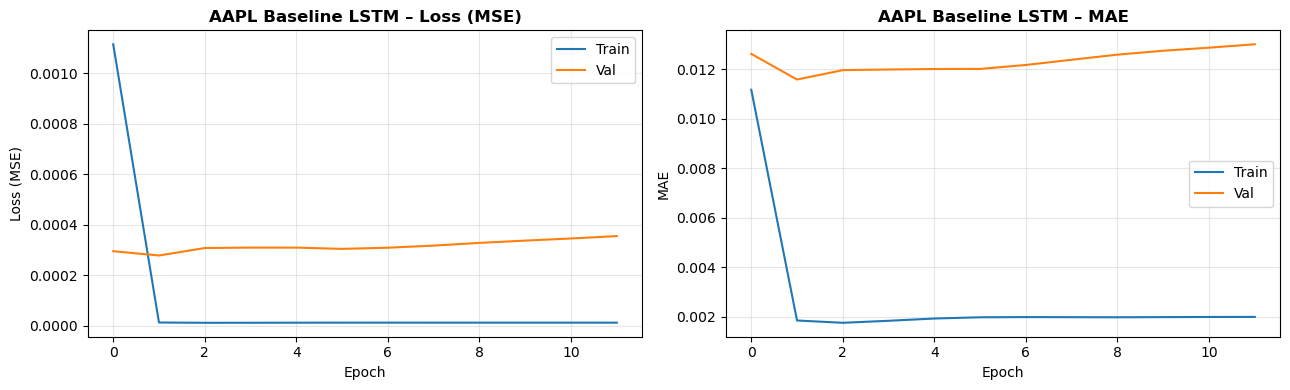

In [40]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, m, lbl in zip(axes, ['loss','mae'], ['Loss (MSE)','MAE']):
        ax.plot(hist.history[m],'#1f77b4', lw=1.5, label='Train')
        ax.plot(hist.history[f'val_{m}'],'#ff7f0e', lw=1.5, label='Val')
        ax.set_title(f'{title} – {lbl}', fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel(lbl); ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

plot_history(history_aapl, 'AAPL Baseline LSTM')

##### **B.1.2 AMC Base model**

In [41]:
model1_amd= Sequential([
    LSTM(50, activation='relu', input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [42]:
model1_amd.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model1_amd.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae','mape']
)

In [44]:
history_amd = model1_amd.fit(
    X_amd_train, y_amd_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_amd_val, y_amd_val),
    callbacks = [early_stop],
    verbose = 1
)

Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0142 - mae: 0.0665 - mape: 47.9623 - val_loss: 3.1066e-04 - val_mae: 0.0115 - val_mape: 10759.6299
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.6749e-04 - mae: 0.0102 - mape: 7.3588 - val_loss: 3.0738e-04 - val_mae: 0.0117 - val_mape: 11554.8965
Epoch 3/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.6158e-04 - mae: 0.0102 - mape: 7.3595 - val_loss: 3.0302e-04 - val_mae: 0.0118 - val_mape: 12236.1045
Epoch 4/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.5336e-04 - mae: 0.0100 - mape: 7.3029 - val_loss: 2.9463e-04 - val_mae: 0.0117 - val_mape: 12530.7559
Epoch 5/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 2.4291e-04 - mae: 0.0098 - mape: 7.2154 - val_loss: 2.7876e-04 - val_mae: 0.0114 - val_mape: 12600.8740
Epoch 6/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.2856e-04 - mae: 0.0095 - mape: 7.0355 - val_loss: 2.6254e-04 - val_mae: 0.0109 - val_mape: 11513.1387
Epoch 7/50
277/277

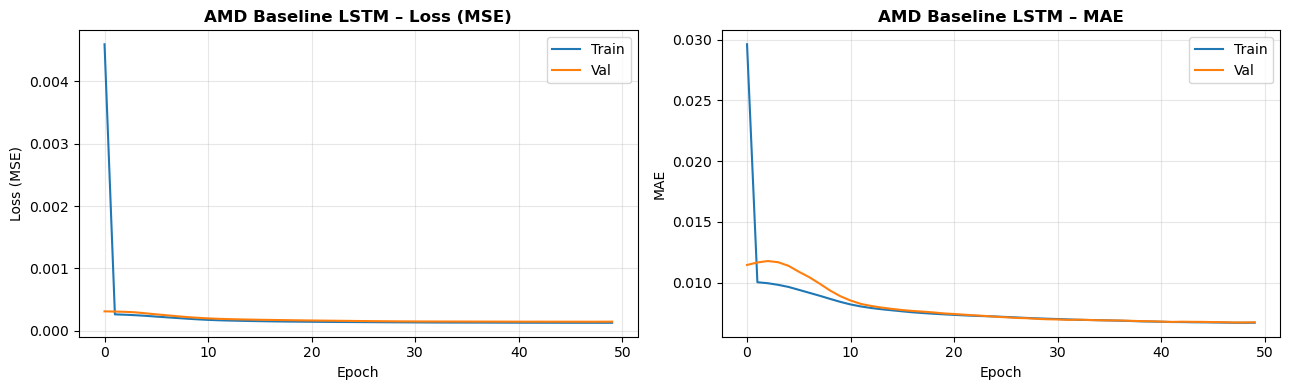

In [46]:
plot_history(history_amd, 'AMD Baseline LSTM')

### **C. modifikasi arsitektur pada nomor 1c untuk mendapatkan unjuk kerja yang optimal**

#### **C.1 Modified Data**

In [49]:
aapl_ret_full = aapl_df.copy()
aapl_ret_full['ret'] = aapl_ret_full['Close'].pct_change()
aapl_ret_full = aapl_ret_full.dropna().reset_index(drop=True)

amd_ret_full = amd_df.copy()
amd_ret_full['ret'] = amd_ret_full['Close'].pct_change()
amd_ret_full = amd_ret_full.dropna().reset_index(drop=True)

MEngubah Output menjadi return percentage harian.

##### **C.1.1 Split Train Test**

In [50]:
#Split train/test pada returns
aapl_ret_train = aapl_ret_full[aapl_ret_full['Date'] < TEST_START_AAPL]
aapl_ret_test = aapl_ret_full[aapl_ret_full['Date'] >= TEST_START_AAPL]
amd_ret_train = amd_ret_full[amd_ret_full['Date'] < TEST_START_AMD]
amd_ret_test = amd_ret_full[amd_ret_full['Date'] >= TEST_START_AMD]

##### **C.1.2 Scaling**

In [51]:
# Scale returns ke [-1, 1] 
aapl_ret_scaler = MinMaxScaler(feature_range=(-1, 1))
amd_ret_scaler  = MinMaxScaler(feature_range=(-1, 1))

aapl_ret_tr_sc = aapl_ret_scaler.fit_transform(aapl_ret_train[['ret']])
aapl_ret_te_sc = aapl_ret_scaler.transform(aapl_ret_test[['ret']])

amd_ret_tr_sc  = amd_ret_scaler.fit_transform(amd_ret_train[['ret']])
amd_ret_te_sc  = amd_ret_scaler.transform(amd_ret_test[['ret']])

##### **C.1.3 Set Windowing**

In [52]:
Xm_aapl_full, ym_aapl_full = create_windows(aapl_ret_tr_sc, WINDOW_SIZE, HORIZON)
Xm_amd_full,  ym_amd_full  = create_windows(amd_ret_tr_sc,  WINDOW_SIZE, HORIZON)

Xm_aapl_test, ym_aapl_test = create_windows(
    np.concatenate([aapl_ret_tr_sc[-WINDOW_SIZE:], aapl_ret_te_sc]), WINDOW_SIZE, HORIZON)
Xm_amd_test,  ym_amd_test  = create_windows(
    np.concatenate([amd_ret_tr_sc[-WINDOW_SIZE:],  amd_ret_te_sc]),  WINDOW_SIZE, HORIZON)

##### **C.1.4 Train Val Split**

In [53]:
Xm_aa_tr,Xm_aa_vl,ym_aa_tr,ym_aa_vl = split_tv(Xm_aapl_full, ym_aapl_full)
Xm_dm_tr,Xm_dm_vl,ym_dm_tr,ym_dm_vl = split_tv(Xm_amd_full,  ym_amd_full)

Xm_aa_tr,Xm_aa_vl = rs(Xm_aa_tr),rs(Xm_aa_vl); Xm_aapl_test=rs(Xm_aapl_test)
Xm_dm_tr,Xm_dm_vl = rs(Xm_dm_tr),rs(Xm_dm_vl); Xm_amd_test =rs(Xm_amd_test)

ym_aa_tr,ym_aa_vl,ym_aapl_test = ym_aa_tr.flatten(),ym_aa_vl.flatten(),ym_aapl_test.flatten()
ym_dm_tr,ym_dm_vl,ym_amd_test  = ym_dm_tr.flatten(),ym_dm_vl.flatten(),ym_amd_test.flatten()

#### **C.2 Modeling (Modified)**

##### **C.2.1 AAPL Modified Model**

In [47]:
model2_aapl = Sequential([
    LSTM(64, activation='tanh', return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    LSTM(32, activation='tanh'),
    Dense(16, activation='relu'),
    Dense(1)
])

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [48]:
model2_aapl.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 5, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
early_stop_new = [
    EarlyStopping('val_loss', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau('val_loss', factor=0.3, patience=5, min_lr=1e-7, verbose=1)
]

In [55]:
model2_aapl.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='huber',
    metrics=['mae','mape']
)

In [56]:
history_aapl_modified = model2_aapl.fit(
    Xm_aa_tr, ym_aa_tr, 
    epochs=60, 
    batch_size=32, 
    validation_data=(Xm_aa_vl, ym_aa_vl),
    callbacks=early_stop_new, 
    verbose=1
)

Epoch 1/60
272/272 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0061 - mae: 0.0786 - mape: 48.2462 - val_loss: 6.9786e-04 - val_mae: 0.0258 - val_mape: 14.7557 - learning_rate: 0.0010
Epoch 2/60
272/272 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0026 - mae: 0.0502 - mape: 39.2090 - val_loss: 6.9688e-04 - val_mae: 0.0258 - val_mape: 14.8269 - learning_rate: 0.0010
Epoch 3/60
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0026 - mae: 0.0500 - mape: 39.2594 - val_loss: 6.9401e-04 - val_mae: 0.0258 - val_mape: 14.7700 - learning_rate: 0.0010
Epoch 4/60
272/272 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0026 - mae: 0.0500 - mape: 39.2788 - val_loss: 6.9602e-04 - val_mae: 0.0258 - val_mape: 14.8404 - learning_rate: 0.0010
Epoch 5/60
272/272 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0026 - mae: 0.0499 - mape: 39.2920 - val_loss: 6.9611e-04 - val_mae: 0.0258 - val_mape: 14.8514 - learning_rate: 0.0010
Epoch 6/60
271/272 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0026 - mae: 0.0500 - ma

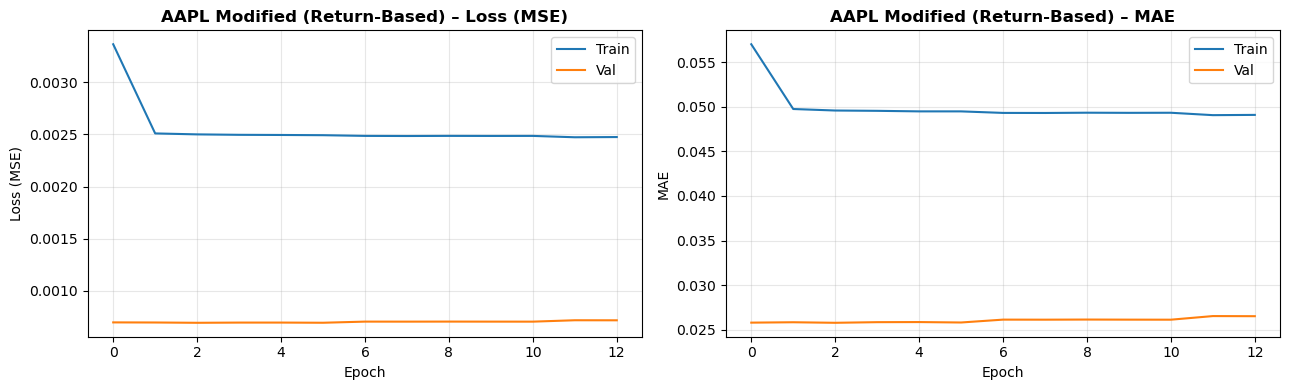

In [57]:
plot_history(history_aapl_modified, 'AAPL Modified (Return-Based)')

##### **C.2.2 AMD Modified Model**

In [58]:
model2_amd = Sequential([
    LSTM(64, activation='tanh', return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    LSTM(32, activation='tanh'),
    Dense(16, activation='relu'),
    Dense(1)
])

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [59]:
model2_amd.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 5, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
model2_amd.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='huber',
    metrics=['mae','mape']
)

In [63]:
history_amd_modified = model2_amd.fit(
    Xm_dm_tr, ym_dm_tr, 
    epochs=60, 
    batch_size=32, 
    validation_data=(Xm_dm_vl, ym_dm_vl),
    callbacks=early_stop_new, 
    verbose=1
)

Epoch 1/60
277/277 ━━━━━━━━━━━━━━━━━━━━ 23s 25ms/step - loss: 0.0046 - mae: 0.0700 - mape: 1270.0150 - val_loss: 0.0045 - val_mae: 0.0634 - val_mape: 161.2379 - learning_rate: 0.0010
Epoch 2/60
277/277 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.0034 - mae: 0.0583 - mape: 1337.5844 - val_loss: 0.0045 - val_mae: 0.0632 - val_mape: 161.3403 - learning_rate: 0.0010
Epoch 3/60
277/277 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0034 - mae: 0.0582 - mape: 1340.4301 - val_loss: 0.0045 - val_mae: 0.0631 - val_mape: 160.5308 - learning_rate: 0.0010
Epoch 4/60
277/277 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0034 - mae: 0.0581 - mape: 1345.2056 - val_loss: 0.0045 - val_mae: 0.0630 - val_mape: 160.0672 - learning_rate: 0.0010
Epoch 5/60
277/277 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0034 - mae: 0.0581 - mape: 1323.2212 - val_loss: 0.0045 - val_mae: 0.0629 - val_mape: 159.3026 - learning_rate: 0.0010
Epoch 6/60
273/277 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0034 - mae: 0.0581 - mape:

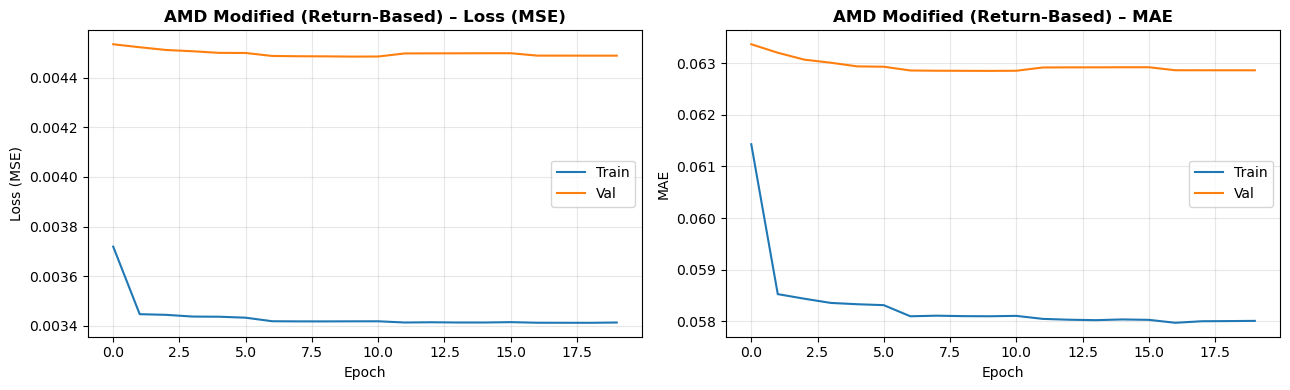

In [65]:
plot_history(history_amd_modified, 'AMD Modified (Return-Based)')

### **D. Lakukan evaluasi unjuk kerja kedua arsitektur di atas pada test set dengan mencari nilai RMSE, MAE dan MAPE**

#### **D.1 Evaluasi Model Baseline**

In [66]:
def eval_baseline(model, X_test, y_test_sc, scaler, label):
    p = np.clip(model.predict(X_test, verbose=0).flatten(), 0, 1)
    yp = scaler.inverse_transform(p.reshape(-1,1)).flatten()
    yt = scaler.inverse_transform(y_test_sc.reshape(-1,1)).flatten()
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae  = mean_absolute_error(yt, yp)
    mape = np.mean(np.abs((yt-yp)/yt))*100
    print(f'  {label:<32s} RMSE={rmse:8.4f}  MAE={mae:8.4f}  MAPE={mape:7.4f}%')
    return yt, yp, rmse, mae, mape

##### **D.1.1 Evaluasi AAP Base Model**

In [70]:
yat_b, yap_b, ab_rmse, ab_mae, ab_mape = eval_baseline(model1_aapl, X_aapl_test, y_aapl_test, aapl_scaler, 'Baseline LSTM (harga)')

  Baseline LSTM (harga)            RMSE= 37.5808  MAE= 23.9459  MAPE= 8.4817%


##### **D.1.2 Evaluasi AMD Base Model**

In [71]:
ydt_b, ydp_b, db_rmse, db_mae, db_mape = eval_baseline(model1_amd, X_amd_test, y_amd_test, amd_scaler, 'Baseline LSTM (harga)')

  Baseline LSTM (harga)            RMSE=  2.1469  MAE=  1.2916  MAPE= 3.2087%


#### **D.2 Evaluasi Modified Model**

In [72]:
def eval_modified(model, X_test, ret_scaler, test_close_actual, label):
    p = model.predict(X_test, verbose=0).flatten()
    pred_ret = ret_scaler.inverse_transform(p.reshape(-1,1)).flatten()
    p_act = test_close_actual.values if hasattr(test_close_actual,'values') else test_close_actual
    n = min(len(p_act)-1, len(pred_ret))
    yp = p_act[:n] * (1 + pred_ret[:n])
    yt = p_act[1:n+1]
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae  = mean_absolute_error(yt, yp)
    mape = np.mean(np.abs((yt-yp)/yt))*100
    print(f'  {label:<32s} RMSE={rmse:8.4f}  MAE={mae:8.4f}  MAPE={mape:7.4f}%')
    return yt, yp, rmse, mae, mape

##### **D.2.1 Evaluasi AAP Modified**

In [77]:
yat_m, yap_m, am_rmse, am_mae, am_mape = eval_modified(model2_aapl, X_aapl_test, aapl_ret_scaler, aapl_test['Close'], 'Modified (return-based)')

  Modified (return-based)          RMSE=  8.6306  MAE=  7.1669  MAPE= 3.1247%


##### **D.2.2 Evaluasi AMD Modified**

In [76]:
ydt_m, ydp_m, dm_rmse, dm_mae, dm_mape = eval_modified(model2_amd, Xm_amd_test, amd_ret_scaler, amd_test['Close'], 'Modified (return-based)')

  Modified (return-based)          RMSE=  1.3776  MAE=  0.9095  MAPE= 2.4380%


In [80]:
df_res = pd.DataFrame({
    'Stock'   : ['AAPL','AAPL','AMD','AMD'],
    'Model'   : ['Baseline LSTM','Modified (Return)','Baseline LSTM','Modified (Return)'],
    'RMSE'    : [ab_rmse,am_rmse,db_rmse,dm_rmse],
    'MAE'     : [ab_mae, am_mae, db_mae, dm_mae],
    'MAPE (%)': [ab_mape,am_mape,db_mape,dm_mape]
}).set_index(['Stock','Model'])

display(df_res.style
    .format({'RMSE':'{:.4f}','MAE':'{:.4f}','MAPE (%)':'{:.4f}%'}))

**VIsualisasi**

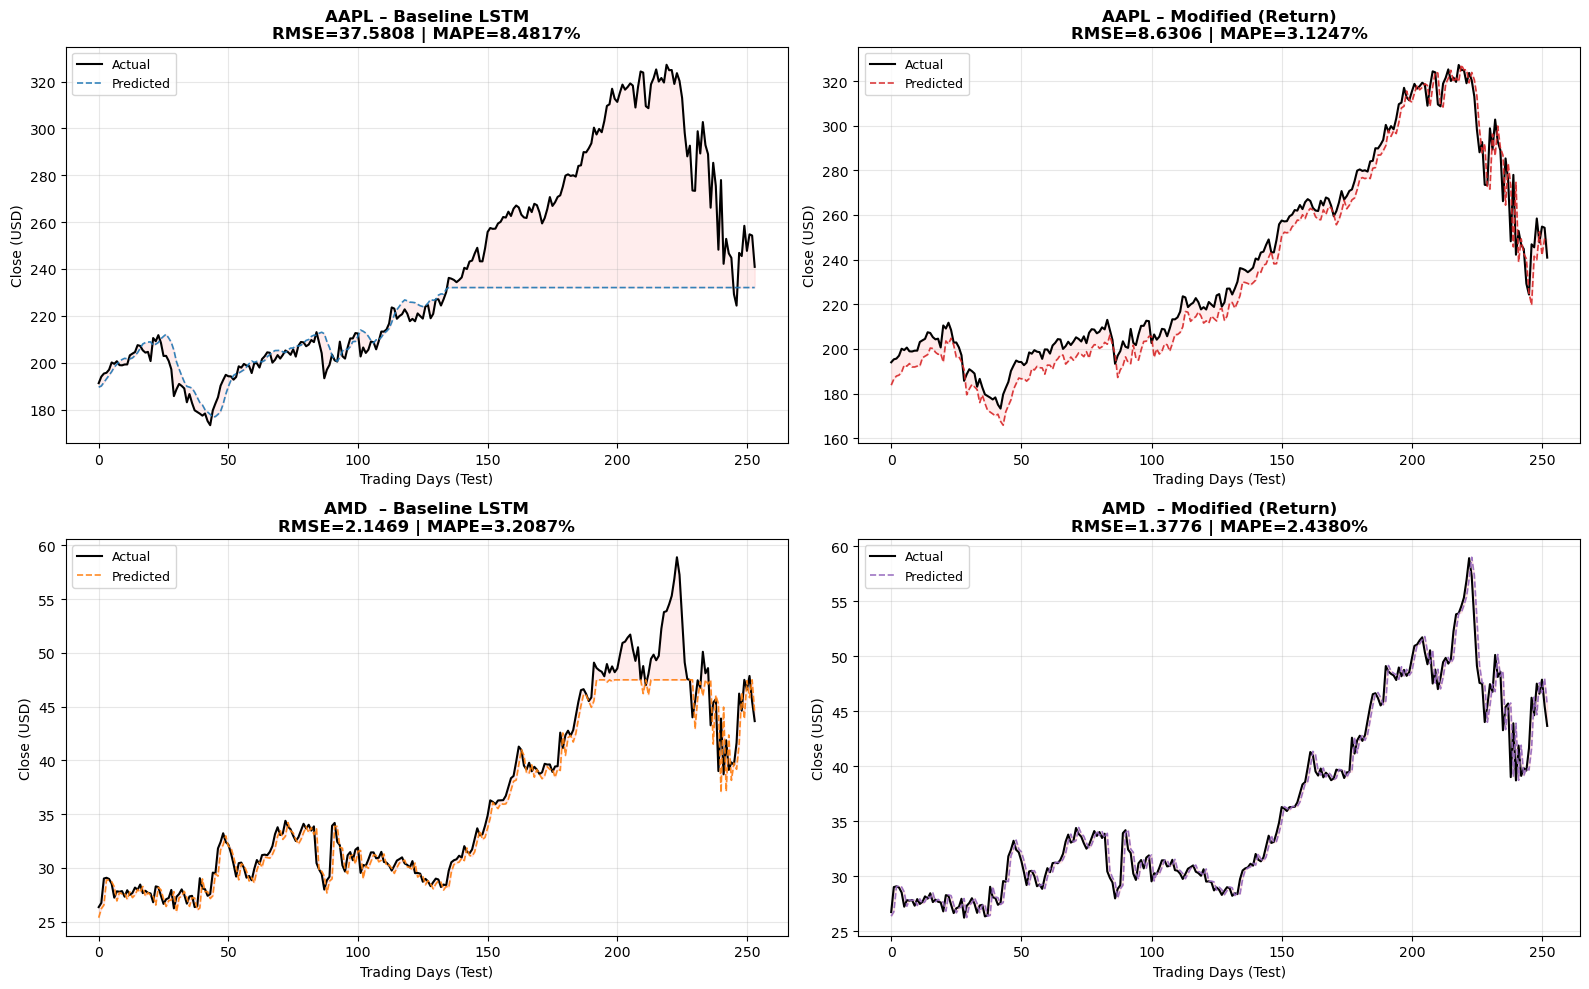

In [81]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for title, yt, yp, color, ax in [
    ('AAPL – Baseline LSTM', yat_b, yap_b, '#1f77b4', axes[0,0]),
    ('AAPL – Modified (Return)', yat_m, yap_m, '#d62728', axes[0,1]),
    ('AMD  – Baseline LSTM', ydt_b, ydp_b, '#ff7f0e', axes[1,0]),
    ('AMD  – Modified (Return)', ydt_m, ydp_m, '#9467bd', axes[1,1]),
]:
    x = range(len(yt))
    ax.plot(x, yt, 'black', lw=1.5, label='Actual')
    ax.plot(x, yp, color, lw=1.2, ls='--', alpha=0.9, label='Predicted')
    ax.fill_between(x, yt, yp, alpha=0.07, color='red')
    r = np.sqrt(mean_squared_error(yt, yp)); mp = np.mean(np.abs((yt-yp)/yt))*100
    ax.set_title(f'{title}\nRMSE={r:.4f} | MAPE={mp:.4f}%', fontweight='bold')
    ax.set_xlabel('Trading Days (Test)'); ax.set_ylabel('Close (USD)')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('predictions_comparison.png', dpi=150, bbox_inches='tight')
plt.show()